In [1]:
!pip install colorama matplotlib pandas scikit-learn reportlab >/dev/null

In [2]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import json
import zipfile
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from colorama import init as colorama_init, Fore, Style
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)
import urllib.request
import warnings
warnings.filterwarnings("ignore")



In [3]:
# ========== INITIALIZATION ==========
colorama_init(autoreset=True)
def title(s): return Fore.CYAN + Style.BRIGHT + s + Style.RESET_ALL
def info(s): return Fore.YELLOW + s + Style.RESET_ALL
def good(s): return Fore.GREEN + s + Style.RESET_ALL
def bad(s): return Fore.RED + s + Style.RESET_ALL
def bold(s): return Style.BRIGHT + s + Style.RESET_ALL


In [4]:
# ========== CONFIG ==========
OUT = Path("wine-quality-complete")
FIGS = OUT / "figs"
DATA_PATH = Path("winequality-red.csv")
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
RANDOM_STATE = 42
KS = list(range(1, 16, 2))
METRICS = ['euclidean', 'manhattan', 'minkowski']
CV_SPLITS = 3
P_MINKOWSKI = 3

OUT.mkdir(exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)



In [6]:
# ========== CORE FUNCTIONS ==========
def ensure_dataset(path=DATA_PATH):
    if path.exists():
        print(info(f"Dataset found: {path}"))
        return path
    print(info("Downloading dataset from UCI..."))
    urllib.request.urlretrieve(UCI_URL, str(path))
    print(info(f"Downloaded: {path}"))
    return path


In [7]:
def ensure_numpy(arr, dtype=None):
    arr = np.asarray(arr)
    if dtype is not None:
        arr = arr.astype(dtype, copy=False)
    return arr


In [8]:
def pairwise_distances(A, B, metric='euclidean', p=3):
    A = np.asarray(A)
    B = np.asarray(B)
    if metric == 'euclidean':
        A2 = np.sum(A**2, axis=1)[:, None]
        B2 = np.sum(B**2, axis=1)[None, :]
        AB = A.dot(B.T)
        return np.sqrt(np.maximum(A2 + B2 - 2*AB, 0.0))
    elif metric == 'manhattan':
        return np.sum(np.abs(A[:, None, :] - B[None, :, :]), axis=2)
    elif metric == 'minkowski':
        return np.sum(np.abs(A[:, None, :] - B[None, :, :])**p, axis=2)**(1.0/p)
    else:
        raise ValueError("Unknown metric")


In [9]:
def knn_reg_predict(X_train, y_train, X_test, k=5, metric='euclidean', weights='uniform', p=3):
    X_train = np.asarray(X_train)
    X_test = np.asarray(X_test)
    y_train = ensure_numpy(y_train, dtype=float)
    n_train = X_train.shape[0]
    k = max(1, min(k, n_train))

    D = pairwise_distances(X_test, X_train, metric=metric, p=p)
    idx = np.argsort(D, axis=1)[:, :k]
    neigh_y = y_train[idx]
    dsel = np.take_along_axis(D, idx, axis=1)

    preds = np.zeros(X_test.shape[0], dtype=float)
    for i in range(len(preds)):
        if (dsel[i] == 0).any():
            preds[i] = np.mean(neigh_y[i][dsel[i] == 0])
        else:
            if weights == 'uniform':
                preds[i] = np.mean(neigh_y[i])
            else:
                w = 1.0 / (dsel[i] + 1e-8)
                preds[i] = np.sum(w * neigh_y[i]) / np.sum(w)
    return preds


In [10]:
def knn_clf_predict(X_train, y_train, X_test, k=5, metric='euclidean', weights='uniform', p=3):
    X_train = np.asarray(X_train)
    X_test = np.asarray(X_test)
    y_train = ensure_numpy(y_train)
    n_train = X_train.shape[0]
    k = max(1, min(k, n_train))

    D = pairwise_distances(X_test, X_train, metric=metric, p=p)
    idx = np.argsort(D, axis=1)[:, :k]
    neigh_y = y_train[idx]
    dsel = np.take_along_axis(D, idx, axis=1)

    m = neigh_y.shape[0]
    preds = np.zeros(m, dtype=int)
    for i in range(m):
        if (dsel[i] == 0).any():
            vals, cnts = np.unique(neigh_y[i][dsel[i] == 0], return_counts=True)
            preds[i] = vals[np.argmax(cnts)]
        else:
            if weights == 'uniform':
                vals, cnts = np.unique(neigh_y[i], return_counts=True)
                preds[i] = vals[np.argmax(cnts)]
            else:
                w = 1.0 / (dsel[i] + 1e-8)
                unique = np.unique(neigh_y[i])
                scores = {u: np.sum(w[neigh_y[i] == u]) for u in unique}
                preds[i] = max(scores.items(), key=lambda x: x[1])[0]
    return preds


In [11]:
def oversample_minority(X, y, random_state=RANDOM_STATE):
    df = pd.DataFrame(X)
    df['label'] = y
    counts = df['label'].value_counts()
    max_count = counts.max()

    parts = []
    for cls in counts.index:
        part = df[df['label'] == cls].sample(max_count, replace=True, random_state=random_state)
        parts.append(part)

    out = pd.concat(parts).sample(frac=1, random_state=random_state).reset_index(drop=True)
    Xb = out.drop(columns=['label']).values
    yb = out['label'].values
    return Xb, yb


In [13]:
# ========== REGRESSION EXPERIMENT ==========
def regression_experiment(Xs, y, test_size=0.3, out_prefix="split", verbose=True):
    results = {}
    X_train, X_test, y_train, y_test = train_test_split(Xs, y, test_size=test_size, random_state=RANDOM_STATE)

    if verbose:
        print(info(f"  Training set: {X_train.shape[0]} samples"))
        print(info(f"  Test set: {X_test.shape[0]} samples"))

    # Baselines
    lr = LinearRegression().fit(X_train, y_train)
    y_lr = lr.predict(X_test)
    results['LinearRegression'] = {
        'RMSE': float(np.sqrt(mean_squared_error(y_test, y_lr))),
        'R2': float(r2_score(y_test, y_lr))
    }

    ridge = Ridge(alpha=1.0).fit(X_train, y_train)
    y_ridge = ridge.predict(X_test)
    results['Ridge'] = {
        'RMSE': float(np.sqrt(mean_squared_error(y_test, y_ridge))),
        'R2': float(r2_score(y_test, y_ridge))
    }

    # k-NN Grid Search
    best = {'rmse': 1e12}
    grid = []
    cv = KFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

    if verbose:
        print(info("  k-NN Regression CV grid search..."))

    for metric in METRICS:
        for k in KS:
            rmses = []
            for tr, va in cv.split(X_train):
                yp = knn_reg_predict(X_train[tr], y_train[tr], X_train[va], k=k, metric=metric, weights='uniform', p=P_MINKOWSKI)
                rmses.append(np.sqrt(mean_squared_error(y_train[va], yp)))

            mean_rmse = float(np.mean(rmses))
            grid.append({'metric': metric, 'k': k, 'cv_rmse': mean_rmse})

            if mean_rmse < best['rmse']:
                best = {'metric': metric, 'k': k, 'rmse': mean_rmse}

            if verbose:
                print(f"    {metric:9s} k={k:2d} cv_rmse={mean_rmse:.4f}")

    # Evaluate best models
    yp_best = knn_reg_predict(X_train, y_train, X_test, k=best['k'], metric=best['metric'], weights='uniform', p=P_MINKOWSKI)
    results['KNN_best_uniform'] = {
        'k': best['k'], 'metric': best['metric'],
        'RMSE': float(np.sqrt(mean_squared_error(y_test, yp_best))),
        'R2': float(r2_score(y_test, yp_best))
    }

    yp_dw = knn_reg_predict(X_train, y_train, X_test, k=best['k'], metric=best['metric'], weights='distance', p=P_MINKOWSKI)
    results['KNN_best_distance_weighted'] = {
        'k': best['k'], 'metric': best['metric'],
        'RMSE': float(np.sqrt(mean_squared_error(y_test, yp_dw))),
        'R2': float(r2_score(y_test, yp_dw))
    }

    # Save files
    pd.DataFrame(grid).to_csv(OUT / f"{out_prefix}_reg_grid.csv", index=False)
    with open(OUT / f"{out_prefix}_reg_results.json", "w") as f:
        json.dump(results, f, indent=2)

    if verbose:
        print(bold("  Regression Results:"))
        for model, stats in results.items():
            color = good if model.startswith('KNN') and stats['RMSE'] == min(v['RMSE'] for v in results.values() if 'RMSE' in v) else info
            print(color(f"    {model:25} RMSE={stats['RMSE']:.4f}  R²={stats['R2']:.4f}"))

    return results, pd.DataFrame(grid)



In [14]:
# ========== CLASSIFICATION EXPERIMENT ==========
def classification_experiment(Xs, y_binary, test_size=0.3, out_prefix="split", verbose=True):
    results = {}
    X_train, X_test, y_train, y_test = train_test_split(Xs, y_binary, test_size=test_size, random_state=RANDOM_STATE, stratify=y_binary)

    if verbose:
        print(info(f"  Training set: {X_train.shape[0]} samples (class dist: {np.bincount(y_train)})"))
        print(info(f"  Test set: {X_test.shape[0]} samples (class dist: {np.bincount(y_test)})"))

    # Oversample training data
    X_tr_bal, y_tr_bal = oversample_minority(X_train, y_train)

    if verbose:
        print(info(f"  After oversampling: {X_tr_bal.shape[0]} samples (class dist: {np.bincount(y_tr_bal)})"))

    # Baselines
    # Logistic Regression
    log = LogisticRegression(max_iter=2000).fit(X_tr_bal, y_tr_bal)
    yp_log = log.predict(X_test)
    results['Logistic'] = {
        'accuracy': float(accuracy_score(y_test, yp_log)),
        'precision': float(precision_score(y_test, yp_log, zero_division=0)),
        'recall': float(recall_score(y_test, yp_log, zero_division=0)),
        'f1': float(f1_score(y_test, yp_log, zero_division=0))
    }
    try:
        proba = log.predict_proba(X_test)[:,1]
        results['Logistic']['roc_auc'] = float(roc_auc_score(y_test, proba))
    except: pass

    # Decision Tree
    dt = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_tr_bal, y_tr_bal)
    yp_dt = dt.predict(X_test)
    results['DecisionTree'] = {
        'accuracy': float(accuracy_score(y_test, yp_dt)),
        'precision': float(precision_score(y_test, yp_dt, zero_division=0)),
        'recall': float(recall_score(y_test, yp_dt, zero_division=0)),
        'f1': float(f1_score(y_test, yp_dt, zero_division=0))
    }

    # Random Forest
    rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE).fit(X_tr_bal, y_tr_bal)
    yp_rf = rf.predict(X_test)
    results['RandomForest'] = {
        'accuracy': float(accuracy_score(y_test, yp_rf)),
        'precision': float(precision_score(y_test, yp_rf, zero_division=0)),
        'recall': float(recall_score(y_test, yp_rf, zero_division=0)),
        'f1': float(f1_score(y_test, yp_rf, zero_division=0))
    }
    try:
        proba_rf = rf.predict_proba(X_test)[:,1]
        results['RandomForest']['roc_auc'] = float(roc_auc_score(y_test, proba_rf))
    except: pass

    # SVM
    svc = SVC(probability=True, random_state=RANDOM_STATE).fit(X_tr_bal, y_tr_bal)
    yp_svc = svc.predict(X_test)
    results['SVM'] = {
        'accuracy': float(accuracy_score(y_test, yp_svc)),
        'precision': float(precision_score(y_test, yp_svc, zero_division=0)),
        'recall': float(recall_score(y_test, yp_svc, zero_division=0)),
        'f1': float(f1_score(y_test, yp_svc, zero_division=0))
    }
    try:
        proba_svc = svc.predict_proba(X_test)[:,1]
        results['SVM']['roc_auc'] = float(roc_auc_score(y_test, proba_svc))
    except: pass

    # k-NN Grid Search
    best = {'score': -1}
    grid = []
    cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

    if verbose:
        print(info("  k-NN Classification CV grid search..."))

    for metric in METRICS:
        for k in KS:
            accs = []
            for tr, va in cv.split(X_tr_bal, y_tr_bal):
                yp = knn_clf_predict(X_tr_bal[tr], y_tr_bal[tr], X_tr_bal[va], k=k, metric=metric, weights='uniform', p=P_MINKOWSKI)
                accs.append(accuracy_score(y_tr_bal[va], yp))

            mean_acc = float(np.mean(accs))
            grid.append({'metric': metric, 'k': k, 'cv_acc': mean_acc})

            if mean_acc > best['score']:
                best = {'metric': metric, 'k': k, 'score': mean_acc}

            if verbose:
                print(f"    {metric:9s} k={k:2d} cv_acc={mean_acc:.4f}")

    # Evaluate best k-NN
    yp_knn = knn_clf_predict(X_tr_bal, y_tr_bal, X_test, k=best['k'], metric=best['metric'], weights='uniform', p=P_MINKOWSKI)
    results['KNN_best_uniform'] = {
        'k': best['k'], 'metric': best['metric'],
        'accuracy': float(accuracy_score(y_test, yp_knn)),
        'precision': float(precision_score(y_test, yp_knn, zero_division=0)),
        'recall': float(recall_score(y_test, yp_knn, zero_division=0)),
        'f1': float(f1_score(y_test, yp_knn, zero_division=0))
    }

    yp_knn_dw = knn_clf_predict(X_tr_bal, y_tr_bal, X_test, k=best['k'], metric=best['metric'], weights='distance', p=P_MINKOWSKI)
    results['KNN_best_distance_weighted'] = {
        'k': best['k'], 'metric': best['metric'],
        'accuracy': float(accuracy_score(y_test, yp_knn_dw)),
        'precision': float(precision_score(y_test, yp_knn_dw, zero_division=0)),
        'recall': float(recall_score(y_test, yp_knn_dw, zero_division=0)),
        'f1': float(f1_score(y_test, yp_knn_dw, zero_division=0))
    }

    # Save files
    pd.DataFrame(grid).to_csv(OUT / f"{out_prefix}_clf_grid.csv", index=False)
    with open(OUT / f"{out_prefix}_clf_results.json", "w") as f:
        json.dump(results, f, indent=2)

    if verbose:
        print(bold("  Classification Results:"))
        for model, stats in results.items():
            color = good if model.startswith('KNN') and stats['accuracy'] == max(v['accuracy'] for v in results.values() if 'accuracy' in v) else info
            extra = f" AUC={stats.get('roc_auc', 'N/A'):.4f}" if 'roc_auc' in stats and stats['roc_auc'] is not None else ""
            print(color(f"    {model:25} Acc={stats['accuracy']:.4f} F1={stats['f1']:.4f}{extra}"))

    return results, pd.DataFrame(grid)



In [15]:
# ========== PLOTTING ==========
def create_plots(reg_grid, clf_grid, split_name, out_prefix):
    # Regression plots
    plt.figure(figsize=(10, 4))
    for metric in METRICS:
        rows = reg_grid[reg_grid['metric'] == metric]
        if not rows.empty:
            plt.plot(rows['k'], rows['cv_rmse'], marker='o', label=f"{metric}")
    plt.title(f"Regression CV RMSE vs k ({split_name})")
    plt.xlabel("k"); plt.ylabel("CV RMSE"); plt.legend(); plt.grid(True, alpha=0.3)
    plt.savefig(FIGS / f"{out_prefix}_reg_rmse_plot.png", bbox_inches='tight', dpi=150)
    plt.show()

    # Classification plots
    plt.figure(figsize=(10, 4))
    for metric in METRICS:
        rows = clf_grid[clf_grid['metric'] == metric]
        if not rows.empty:
            plt.plot(rows['k'], rows['cv_acc'], marker='o', label=f"{metric}")
    plt.title(f"Classification CV Accuracy vs k ({split_name})")
    plt.xlabel("k"); plt.ylabel("CV Accuracy"); plt.legend(); plt.grid(True, alpha=0.3)
    plt.savefig(FIGS / f"{out_prefix}_clf_acc_plot.png", bbox_inches='tight', dpi=150)
    plt.show()



In [16]:
# ========== PDF REPORT ==========
def build_pdf_report(summary_path, out_path):
    with open(summary_path, "r") as f:
        summary = json.load(f)

    with PdfPages(out_path) as pdf:
        # Title page
        plt.figure(figsize=(8.5, 11))
        plt.axis('off')
        plt.text(0.5, 0.8, "Wine Quality Prediction Project", ha='center', fontsize=18, weight='bold')
        plt.text(0.5, 0.75, "k-NN Regression & Classification Analysis", ha='center', fontsize=14)
        plt.text(0.5, 0.7, f"Random State: {RANDOM_STATE}", ha='center', fontsize=10)
        pdf.savefig()
        plt.close()

        # Results summary
        plt.figure(figsize=(8.5, 11))
        plt.axis('off')
        txt = json.dumps(summary, indent=2)
        plt.text(0.01, 0.99, txt, fontsize=6, va='top', family='monospace')
        pdf.savefig()
        plt.close()

        # Include plots if they exist
        for split in ["split70", "split80"]:
            for plot_type in ["reg_rmse_plot", "clf_acc_plot"]:
                plot_path = FIGS / f"{split}_{plot_type}.png"
                if plot_path.exists():
                    img = plt.imread(str(plot_path))
                    plt.figure(figsize=(8.5, 11))
                    plt.imshow(img)
                    plt.axis('off')
                    pdf.savefig()
                    plt.close()


 WINE QUALITY PREDICTION - ULTIMATE VERSION 
Combining beautiful terminal output + complete file generation
Downloaded: winequality-red.csv
Dataset loaded: 1599 samples, 12 features

 RUNNING 70:30 SPLIT EXPERIMENTS

 REGRESSION: Predicting Quality Score
  Training set: 1119 samples
  Test set: 480 samples
  k-NN Regression CV grid search...
    euclidean k= 1 cv_rmse=0.8376
    euclidean k= 3 cv_rmse=0.7169
    euclidean k= 5 cv_rmse=0.6904
    euclidean k= 7 cv_rmse=0.6734
    euclidean k= 9 cv_rmse=0.6639
    euclidean k=11 cv_rmse=0.6582
    euclidean k=13 cv_rmse=0.6528
    euclidean k=15 cv_rmse=0.6516
    manhattan k= 1 cv_rmse=0.8307
    manhattan k= 3 cv_rmse=0.7114
    manhattan k= 5 cv_rmse=0.6828
    manhattan k= 7 cv_rmse=0.6588
    manhattan k= 9 cv_rmse=0.6434
    manhattan k=11 cv_rmse=0.6431
    manhattan k=13 cv_rmse=0.6435
    manhattan k=15 cv_rmse=0.6411
    minkowski k= 1 cv_rmse=0.8440
    minkowski k= 3 cv_rmse=0.7194
    minkowski k= 5 cv_rmse=0.6876
    minkow

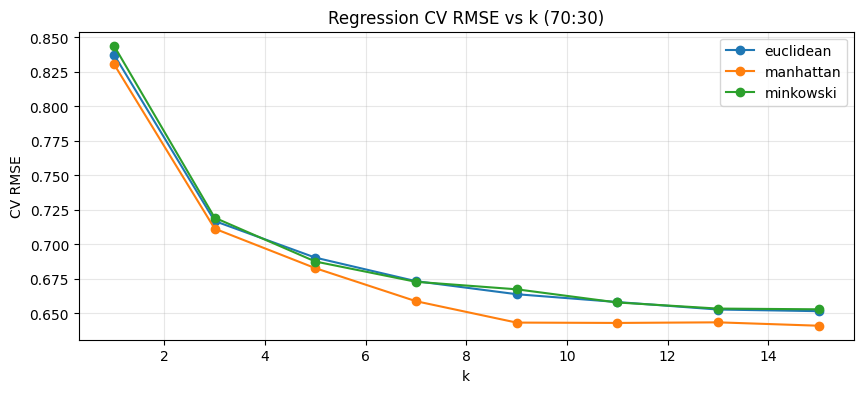

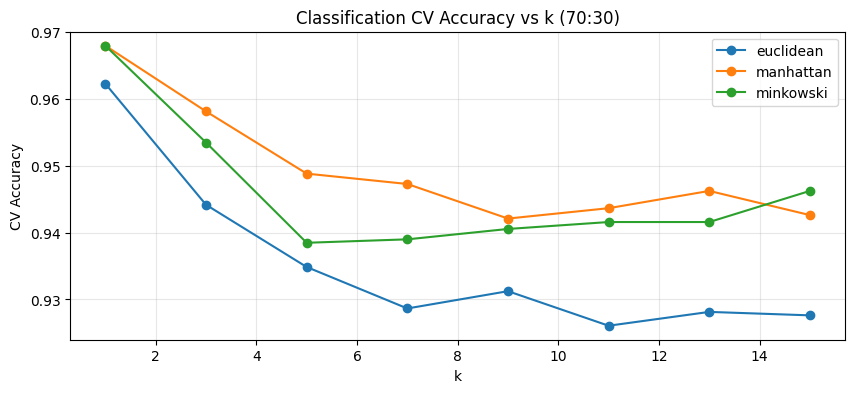


 RUNNING 80:20 SPLIT EXPERIMENTS

 REGRESSION: Predicting Quality Score
  Training set: 1279 samples
  Test set: 320 samples
  k-NN Regression CV grid search...
    euclidean k= 1 cv_rmse=0.8162
    euclidean k= 3 cv_rmse=0.7021
    euclidean k= 5 cv_rmse=0.6684
    euclidean k= 7 cv_rmse=0.6618
    euclidean k= 9 cv_rmse=0.6566
    euclidean k=11 cv_rmse=0.6551
    euclidean k=13 cv_rmse=0.6530
    euclidean k=15 cv_rmse=0.6499
    manhattan k= 1 cv_rmse=0.8219
    manhattan k= 3 cv_rmse=0.7075
    manhattan k= 5 cv_rmse=0.6674
    manhattan k= 7 cv_rmse=0.6525
    manhattan k= 9 cv_rmse=0.6428
    manhattan k=11 cv_rmse=0.6396
    manhattan k=13 cv_rmse=0.6392
    manhattan k=15 cv_rmse=0.6339
    minkowski k= 1 cv_rmse=0.8160
    minkowski k= 3 cv_rmse=0.6931
    minkowski k= 5 cv_rmse=0.6667
    minkowski k= 7 cv_rmse=0.6585
    minkowski k= 9 cv_rmse=0.6537
    minkowski k=11 cv_rmse=0.6465
    minkowski k=13 cv_rmse=0.6421
    minkowski k=15 cv_rmse=0.6411
  Regression Results:


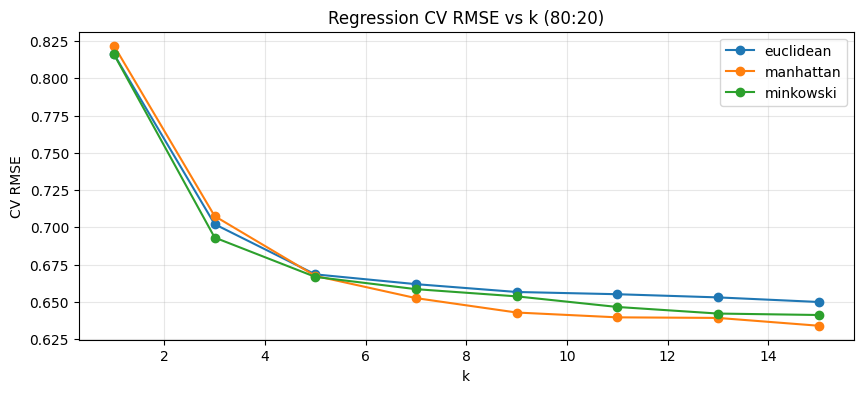

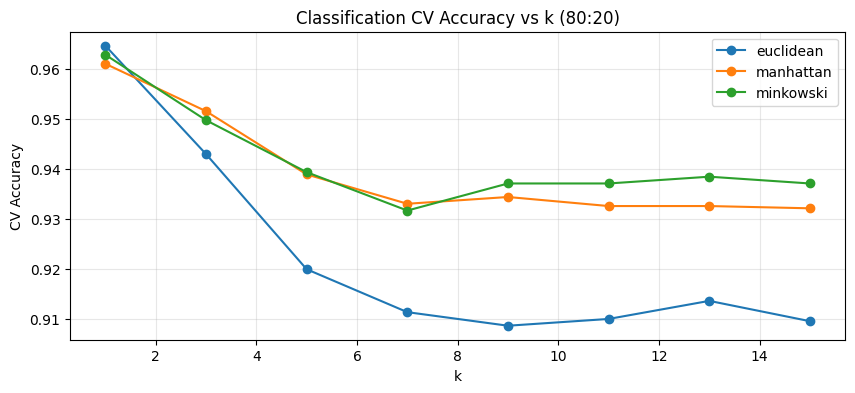


 GENERATING PDF REPORT...

 CREATING SUBMISSION PACKAGE...

 SUCCESS! Project completed!
 Output folder: /content/wine-quality-complete
 Submission package: wine-quality-complete.zip
 PDF Report: wine-quality-complete/Wine_Quality_Complete_Report.pdf
 Plots: /content/wine-quality-complete/figs


In [17]:
# ========== MAIN EXECUTION ==========
def main():
    print(title(" WINE QUALITY PREDICTION - ULTIMATE VERSION "))
    print(title("Combining beautiful terminal output + complete file generation"))

    # Load and prepare data
    ensure_dataset()
    df = pd.read_csv(DATA_PATH, sep=';')
    print(info(f"Dataset loaded: {df.shape[0]} samples, {df.shape[1]} features"))

    # Basic stats
    df.describe().to_csv(OUT / "summary_stats.csv")

    # Prepare features
    X = df.drop('quality', axis=1).values
    y = df['quality'].values.astype(float)
    scaler = StandardScaler().fit(X)
    Xs = scaler.transform(X)

    # Binary classification target
    y_binary = (y >= 7).astype(int)

    all_results = {}

    # Run experiments for both splits
    splits = [0.30, 0.20]
    for test_size in splits:
        split_name = f"{int((1-test_size)*100)}:{int(test_size*100)}"
        print(title(f"\n RUNNING {split_name} SPLIT EXPERIMENTS"))
        print(title("="*50))

        # Regression
        print(bold("\n REGRESSION: Predicting Quality Score"))
        reg_results, reg_grid = regression_experiment(Xs, y, test_size, f"split{int((1-test_size)*100)}", verbose=True)

        # Classification
        print(bold("\n CLASSIFICATION: Good vs Bad Wine"))
        clf_results, clf_grid = classification_experiment(Xs, y_binary, test_size, f"split{int((1-test_size)*100)}", verbose=True)

        # Store results
        all_results[f"reg_{split_name.replace(':', '_')}"] = reg_results
        all_results[f"clf_{split_name.replace(':', '_')}"] = clf_results

        # Create plots
        print(bold("\n GENERATING PLOTS..."))
        create_plots(reg_grid, clf_grid, split_name, f"split{int((1-test_size)*100)}")

    # Save comprehensive results
    with open(OUT / "summary_results.json", "w") as f:
        json.dump(all_results, f, indent=2)

    # Generate PDF report
    print(bold("\n GENERATING PDF REPORT..."))
    build_pdf_report(OUT / "summary_results.json", OUT / "Wine_Quality_Complete_Report.pdf")

    # Create ZIP package
    print(bold("\n CREATING SUBMISSION PACKAGE..."))
    with zipfile.ZipFile("wine-quality-complete.zip", "w", zipfile.ZIP_DEFLATED) as zf:
        for root, _, files in os.walk(OUT):
            for file in files:
                full = os.path.join(root, file)
                arc = os.path.relpath(full, OUT.parent)
                zf.write(full, arc)

    print(good("\n SUCCESS! Project completed!"))
    print(good(f" Output folder: {OUT.resolve()}"))
    print(good(f" Submission package: wine-quality-complete.zip"))
    print(good(f" PDF Report: {OUT}/Wine_Quality_Complete_Report.pdf"))
    print(good(f" Plots: {FIGS.resolve()}"))

if __name__ == "__main__":
    main()